# 03. Huấn luyện và tìm siêu tham số

**Đề tài:** Hệ thống khuyến nghị cây trồng

Thử nghiệm **SoftMax, Naive Bayes, KNN, SVM, Decision Tree và Random Forest**.
Mỗi thuật toán có hai cấu hình: mặc định và tối ưu bằng `GridSearchCV`.

- Dùng dữ liệu train chưa chuẩn hóa từ notebook `02_data_preprocessing`.
- Dùng **KFold có phân tầng (`StratifiedKFold`), 5 fold**, trộn dữ liệu với seed 42.
  Các thuật toán và cấu hình dùng chung chính xác các fold để so sánh.
- `StandardScaler` nằm trong `Pipeline` của SoftMax, KNN và SVM, chỉ fit trên
  phần train của từng fold. Gaussian Naive Bayes và các mô hình cây dùng dữ liệu gốc.
- GridSearch chọn cấu hình theo **F1-macro trung bình trên validation**; đồng thời
  ghi thêm Accuracy và độ lệch chuẩn F1-macro để đánh giá hiệu quả, độ ổn định.
- Kết quả CV của cấu hình được GridSearch chọn là kết quả dùng để tối ưu,
  không phải đánh giá độc lập. **Tập test chỉ được đánh giá ở notebook 04**.

Notebook lưu checkpoint để notebook 04 có thể chạy sau khi khởi động lại kernel.
Chỉ thực hiện thử nghiệm và đánh giá, không tích hợp mô hình vào ứng dụng.

**Thứ tự thực hiện:** 1. SoftMax → 2. KNN → 3. Naive Bayes → 4. SVM → 5. Decision Tree → 6. Random Forest.
Mỗi mô hình có một mục và cell huấn luyện riêng bên dưới.

## Thư viện và cấu hình

SoftMax được cài đặt bằng `LogisticRegression(solver="lbfgs")`: với 22 lớp,
mô hình tối ưu hàm mất mát multinomial và dùng SoftMax để tính xác suất lớp.
Naive Bayes dùng biến thể Gaussian vì các đặc trưng là số liên tục.

In [1]:
import hashlib
import json
import os
import platform
from datetime import datetime
from pathlib import Path
from time import perf_counter
from uuid import uuid4

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from joblib import parallel_backend
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
data_dir = project_dir / "data" / "processed"
notebook_dir = project_dir / "notebooks"
checkpoint_path = notebook_dir / "model_training_results.joblib"

RANDOM_STATE = 42
N_SPLITS = 5
N_JOBS = min(4, max(1, (os.cpu_count() or 2) - 1))
SCORING = {
    "accuracy": "accuracy",
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}
# Các cột CV thuộc bộ 13 tiêu chí; chỉ số test và Train_f1_macro được bổ sung ở notebook 04.
CV_COLUMNS = [
    "Model", "Configuration", "CV_accuracy_mean", "CV_f1_macro_mean",
    "CV_f1_macro_std", "CV_train_validation_gap_F1", "Preprocessing", "Best_grid_parameters",
]
plt.rcParams.update({"font.family": "Arial", "axes.unicode_minus": False})
pd.set_option("display.max_colwidth", 100)
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__}")
print(f"CV: {N_SPLITS} fold có phân tầng | seed: {RANDOM_STATE} | số luồng: {N_JOBS}")

Python 3.12.9 | scikit-learn 1.9.0
CV: 5 fold có phân tầng | seed: 42 | số luồng: 4


## Đọc dữ liệu train và tạo các fold



In [2]:
required_files = ["X_train.csv", "y_train.csv", "X_test.csv", "y_test.csv"]
missing_files = [name for name in required_files if not (data_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Chạy notebook 02 trước. Thiếu dữ liệu: {missing_files}")

data_hashes = {
    name: hashlib.sha256((data_dir / name).read_bytes()).hexdigest()
    for name in required_files
}
X_train = pd.read_csv(data_dir / "X_train.csv")
y_train_frame = pd.read_csv(data_dir / "y_train.csv")
expected_features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
assert X_train.columns.tolist() == expected_features, "Sai thứ tự/tên đặc trưng."
assert y_train_frame.columns.tolist() == ["label"], "File nhãn phải có một cột label."
y_train = y_train_frame["label"]
assert len(X_train) == len(y_train) and len(X_train) > 0
assert not y_train.isna().any()
assert np.isfinite(X_train.to_numpy(dtype=float)).all()
assert y_train.nunique() > 2, "SoftMax trong thử nghiệm này dùng cho phân loại đa lớp."
assert y_train.value_counts().min() >= N_SPLITS

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, y_train))
fold_summary = pd.DataFrame([
    {"Fold": fold, "Train_samples": len(train_idx), "Validation_samples": len(valid_idx),
     "Train_classes": y_train.iloc[train_idx].nunique(),
     "Validation_classes": y_train.iloc[valid_idx].nunique()}
    for fold, (train_idx, valid_idx) in enumerate(cv_splits, 1)
])
print(f"Dữ liệu train: {X_train.shape[0]} mẫu, {X_train.shape[1]} đặc trưng, {y_train.nunique()} lớp.")
display(fold_summary)

Dữ liệu train: 1760 mẫu, 7 đặc trưng, 22 lớp.


,Fold,Train_samples,Validation_samples,Train_classes,Validation_classes
0,1,1408,352,22,22
1,2,1408,352,22,22
2,3,1408,352,22,22
3,4,1408,352,22,22
4,5,1408,352,22,22


## Quy trình KFold và GridSearch dùng chung

Với mỗi thuật toán: đánh giá cấu hình mặc định trên 5 fold, fit lại trên toàn
bộ train, rồi chạy GridSearch trên cùng 5 fold. Pipeline tốt nhất được
`GridSearchCV(refit="f1_macro")` tự fit lại trên toàn bộ train.
Độ lệch chuẩn CV dùng `ddof=0`, thống nhất với `GridSearchCV`.
Nếu một cấu hình không dự đoán lớp nào đó, F1 của lớp được
quy ước bằng 0 (`zero_division=0`), thống nhất với bước đánh giá test.

In [3]:
experiments = {}
fitted_models = {}
summary_rows, fold_rows, grid_rows = [], [], []
training_durations = []
started_at = datetime.now().astimezone().isoformat(timespec="seconds")
run_id = uuid4().hex

def train_model(name):
    spec = experiments[name]
    print(f"Đang huấn luyện {name} ...", flush=True)
    model_start = perf_counter()
    pipeline = Pipeline([
        ("scaler", StandardScaler() if spec["scale"] else "passthrough"),
        ("model", spec["estimator"]),
    ])
    with threadpool_limits(limits=1), parallel_backend("threading", n_jobs=N_JOBS):
        baseline_cv = cross_validate(
            pipeline, X_train, y_train, cv=cv_splits, scoring=SCORING,
            n_jobs=N_JOBS, return_train_score=True, error_score="raise",
        )
        pipeline.fit(X_train, y_train)
        search = GridSearchCV(
            pipeline, param_grid=spec["grid"], scoring=SCORING, refit="f1_macro",
            cv=cv_splits, n_jobs=N_JOBS, return_train_score=True, error_score="raise",
        )
        search.fit(X_train, y_train)
    training_durations.append(perf_counter() - model_start)

    results = search.cv_results_
    best_index = search.best_index_
    for candidate_index, params in enumerate(results["params"]):
        grid_rows.append({
            "Model": name, "Candidate": candidate_index + 1,
            "Parameters": json.dumps(params, ensure_ascii=False, sort_keys=True),
            "Rank_CV_F1_macro": int(results["rank_test_f1_macro"][candidate_index]),
            "Selected": candidate_index == best_index,
            "CV_accuracy_mean": float(results["mean_test_accuracy"][candidate_index]),
            "CV_f1_macro_mean": float(results["mean_test_f1_macro"][candidate_index]),
            "CV_f1_macro_std": float(results["std_test_f1_macro"][candidate_index]),
            "CV_train_validation_gap_F1": float(
                results["mean_train_f1_macro"][candidate_index]
                - results["mean_test_f1_macro"][candidate_index]
            ),
        })

    fitted_models[name] = {"Mặc định": pipeline, "GridSearch": search.best_estimator_}
    for variant in ("Mặc định", "GridSearch"):
        def fold_scores(partition, metric):
            if variant == "Mặc định":
                return np.asarray(baseline_cv[f"{partition}_{metric}"])
            return np.array([
                results[f"split{fold}_{partition}_{metric}"][best_index]
                for fold in range(N_SPLITS)
            ])

        validation_accuracy = fold_scores("test", "accuracy")
        validation_f1 = fold_scores("test", "f1_macro")
        train_f1 = fold_scores("train", "f1_macro")
        summary_rows.append({
            "Model": name, "Configuration": variant,
            "CV_accuracy_mean": float(validation_accuracy.mean()),
            "CV_f1_macro_mean": float(validation_f1.mean()),
            "CV_f1_macro_std": float(validation_f1.std(ddof=0)),
            "CV_train_validation_gap_F1": float(train_f1.mean() - validation_f1.mean()),
            "Preprocessing": "StandardScaler" if spec["scale"] else "Dữ liệu gốc",
            "Best_grid_parameters": "{}" if variant == "Mặc định" else json.dumps(search.best_params_, sort_keys=True),
        })
        for fold, (train_idx, valid_idx) in enumerate(cv_splits):
            fold_rows.append({
                "Model": name, "Configuration": variant, "Fold": fold + 1,
                "Train_samples": len(train_idx), "Validation_samples": len(valid_idx),
                "Train_f1_macro": float(train_f1[fold]),
                "Validation_accuracy": float(validation_accuracy[fold]),
                "Validation_f1_macro": float(validation_f1[fold]),
            })

    print(f"  Hoàn tất {name}: CV F1-macro mặc định={summary_rows[-2]['CV_f1_macro_mean']:.4f}; "
          f"GridSearch={summary_rows[-1]['CV_f1_macro_mean']:.4f}; "
          f"tham số={search.best_params_}", flush=True)

## 1. SoftMax

Hồi quy logistic đa lớp với SoftMax, chuẩn hóa bằng StandardScaler; tìm hệ số C.

Huấn luyện mặc định và GridSearch trên cùng 5 fold. Kết quả ngay dưới cell gồm các chỉ số CV và 5 ứng viên GridSearch đứng đầu.

In [4]:
experiments["SoftMax"] = {
    "estimator": LogisticRegression(solver="lbfgs", max_iter=5000, random_state=RANDOM_STATE),
    "scale": True,
    "grid": {"model__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
}

train_model("SoftMax")

model_summary = pd.DataFrame(summary_rows)
display(model_summary.loc[model_summary["Model"] == "SoftMax", CV_COLUMNS])
model_grid = pd.DataFrame(grid_rows)
display(model_grid.loc[model_grid["Model"] == "SoftMax"].sort_values(
    ["Rank_CV_F1_macro", "Candidate"]
).head(5)[["Candidate", "Parameters", "Rank_CV_F1_macro", "CV_f1_macro_mean", "CV_f1_macro_std", "Selected"]])

Đang huấn luyện SoftMax ...
  Hoàn tất SoftMax: CV F1-macro mặc định=0.9678; GridSearch=0.9776; tham số={'model__C': 100.0}


,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,SoftMax,Mặc định,0.968182,0.967824,0.006765,0.006608,StandardScaler,{}
1,SoftMax,GridSearch,0.977841,0.977581,0.005849,0.012600,StandardScaler,"{""model__C"": 100.0}"


,Candidate,Parameters,Rank_CV_F1_macro,CV_f1_macro_mean,CV_f1_macro_std,Selected
5,6,"{""model__C"": 100.0}",1,0.977581,0.005849,True
4,5,"{""model__C"": 10.0}",2,0.976997,0.007324,False
3,4,"{""model__C"": 1.0}",3,0.967824,0.006765,False
2,3,"{""model__C"": 0.1}",4,0.930149,0.009726,False
1,2,"{""model__C"": 0.01}",5,0.768258,0.015654,False


## 2. KNN

KNN, chuẩn hóa bằng StandardScaler; tìm số láng giềng, trọng số và khoảng cách.

Huấn luyện mặc định và GridSearch trên cùng 5 fold. Kết quả ngay dưới cell gồm các chỉ số CV và 5 ứng viên GridSearch đứng đầu.

In [5]:
experiments["KNN"] = {
    "estimator": KNeighborsClassifier(),
    "scale": True,
    "grid": {"model__n_neighbors": [3, 5, 7, 9, 11, 15],
             "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
}

train_model("KNN")

model_summary = pd.DataFrame(summary_rows)
display(model_summary.loc[model_summary["Model"] == "KNN", CV_COLUMNS])
model_grid = pd.DataFrame(grid_rows)
display(model_grid.loc[model_grid["Model"] == "KNN"].sort_values(
    ["Rank_CV_F1_macro", "Candidate"]
).head(5)[["Candidate", "Parameters", "Rank_CV_F1_macro", "CV_f1_macro_mean", "CV_f1_macro_std", "Selected"]])

Đang huấn luyện KNN ...
  Hoàn tất KNN: CV F1-macro mặc định=0.9650; GridSearch=0.9754; tham số={'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance'}


,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
2,KNN,Mặc định,0.965341,0.965011,0.012439,0.017961,StandardScaler,{}
3,KNN,GridSearch,0.975568,0.975440,0.011260,0.024560,StandardScaler,"{""model__n_neighbors"": 5, ""model__p"": 1, ""model__weights"": ""distance""}"


,Candidate,Parameters,Rank_CV_F1_macro,CV_f1_macro_mean,CV_f1_macro_std,Selected
11,6,"{""model__n_neighbors"": 5, ""model__p"": 1, ""model__weights"": ""distance""}",1,0.975440,0.011260,True
7,2,"{""model__n_neighbors"": 3, ""model__p"": 1, ""model__weights"": ""distance""}",2,0.973192,0.011833,False
10,5,"{""model__n_neighbors"": 5, ""model__p"": 1, ""model__weights"": ""uniform""}",3,0.973046,0.010786,False
6,1,"{""model__n_neighbors"": 3, ""model__p"": 1, ""model__weights"": ""uniform""}",4,0.972640,0.011956,False
15,10,"{""model__n_neighbors"": 7, ""model__p"": 1, ""model__weights"": ""distance""}",5,0.972566,0.006955,False


## 3. Naive Bayes

Gaussian Naive Bayes trên các đặc trưng số gốc; tìm hệ số làm trơn phương sai var_smoothing.

Huấn luyện mặc định và GridSearch trên cùng 5 fold. Kết quả ngay dưới cell gồm các chỉ số CV và 5 ứng viên GridSearch đứng đầu.

In [6]:
experiments["Naive Bayes"] = {
    "estimator": GaussianNB(),
    "scale": False,
    "grid": {"model__var_smoothing": np.logspace(-12, -2, 11).tolist()},
}

train_model("Naive Bayes")

model_summary = pd.DataFrame(summary_rows)
display(model_summary.loc[model_summary["Model"] == "Naive Bayes", CV_COLUMNS])
model_grid = pd.DataFrame(grid_rows)
display(model_grid.loc[model_grid["Model"] == "Naive Bayes"].sort_values(
    ["Rank_CV_F1_macro", "Candidate"]
).head(5)[["Candidate", "Parameters", "Rank_CV_F1_macro", "CV_f1_macro_mean", "CV_f1_macro_std", "Selected"]])

Đang huấn luyện Naive Bayes ...
  Hoàn tất Naive Bayes: CV F1-macro mặc định=0.9949; GridSearch=0.9949; tham số={'model__var_smoothing': 1e-12}


,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
4,Naive Bayes,Mặc định,0.994886,0.994871,0.004192,-0.000274,Dữ liệu gốc,{}
5,Naive Bayes,GridSearch,0.994886,0.994871,0.004192,-0.000274,Dữ liệu gốc,"{""model__var_smoothing"": 1e-12}"


,Candidate,Parameters,Rank_CV_F1_macro,CV_f1_macro_mean,CV_f1_macro_std,Selected
30,1,"{""model__var_smoothing"": 1e-12}",1,0.994871,0.004192,True
31,2,"{""model__var_smoothing"": 1e-11}",1,0.994871,0.004192,False
32,3,"{""model__var_smoothing"": 1e-10}",1,0.994871,0.004192,False
33,4,"{""model__var_smoothing"": 1e-09}",1,0.994871,0.004192,False
34,5,"{""model__var_smoothing"": 1e-08}",1,0.994871,0.004192,False


## 4. SVM

Máy vector hỗ trợ, chuẩn hóa bằng StandardScaler; thử kernel linear/rbf, C và gamma.

Huấn luyện mặc định và GridSearch trên cùng 5 fold. Kết quả ngay dưới cell gồm các chỉ số CV và 5 ứng viên GridSearch đứng đầu.

In [7]:
experiments["SVM"] = {
    "estimator": SVC(random_state=RANDOM_STATE),
    "scale": True,
    "grid": [
        {"model__kernel": ["linear"], "model__C": [0.1, 1.0, 10.0, 100.0]},
        {"model__kernel": ["rbf"], "model__C": [0.1, 1.0, 10.0, 100.0],
         "model__gamma": ["scale", 0.01, 0.1, 1.0]},
    ],
}

train_model("SVM")

model_summary = pd.DataFrame(summary_rows)
display(model_summary.loc[model_summary["Model"] == "SVM", CV_COLUMNS])
model_grid = pd.DataFrame(grid_rows)
display(model_grid.loc[model_grid["Model"] == "SVM"].sort_values(
    ["Rank_CV_F1_macro", "Candidate"]
).head(5)[["Candidate", "Parameters", "Rank_CV_F1_macro", "CV_f1_macro_mean", "CV_f1_macro_std", "Selected"]])

Đang huấn luyện SVM ...
  Hoàn tất SVM: CV F1-macro mặc định=0.9788; GridSearch=0.9857; tham số={'model__C': 10.0, 'model__kernel': 'linear'}


,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
6,SVM,Mặc định,0.978977,0.978803,0.010624,0.005327,StandardScaler,{}
7,SVM,GridSearch,0.985795,0.985696,0.001775,0.004910,StandardScaler,"{""model__C"": 10.0, ""model__kernel"": ""linear""}"


,Candidate,Parameters,Rank_CV_F1_macro,CV_f1_macro_mean,CV_f1_macro_std,Selected
43,3,"{""model__C"": 10.0, ""model__kernel"": ""linear""}",1,0.985696,0.001775,True
52,12,"{""model__C"": 1.0, ""model__gamma"": 1.0, ""model__kernel"": ""rbf""}",2,0.984613,0.004663,False
44,4,"{""model__C"": 100.0, ""model__kernel"": ""linear""}",3,0.983423,0.003771,False
56,16,"{""model__C"": 10.0, ""model__gamma"": 1.0, ""model__kernel"": ""rbf""}",4,0.982818,0.002485,False
59,19,"{""model__C"": 100.0, ""model__gamma"": 0.1, ""model__kernel"": ""rbf""}",5,0.982785,0.001700,False


## 5. Decision Tree

Cây quyết định trên dữ liệu gốc; tìm tiêu chí chia, độ sâu tối đa và số mẫu tối thiểu ở lá.

Huấn luyện mặc định và GridSearch trên cùng 5 fold. Kết quả ngay dưới cell gồm các chỉ số CV và 5 ứng viên GridSearch đứng đầu.

In [8]:
experiments["Decision Tree"] = {
    "estimator": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "scale": False,
    "grid": {"model__criterion": ["gini", "entropy"],
             "model__max_depth": [None, 5, 10, 20], "model__min_samples_leaf": [1, 2, 4]},
}

train_model("Decision Tree")

model_summary = pd.DataFrame(summary_rows)
display(model_summary.loc[model_summary["Model"] == "Decision Tree", CV_COLUMNS])
model_grid = pd.DataFrame(grid_rows)
display(model_grid.loc[model_grid["Model"] == "Decision Tree"].sort_values(
    ["Rank_CV_F1_macro", "Candidate"]
).head(5)[["Candidate", "Parameters", "Rank_CV_F1_macro", "CV_f1_macro_mean", "CV_f1_macro_std", "Selected"]])

Đang huấn luyện Decision Tree ...
  Hoàn tất Decision Tree: CV F1-macro mặc định=0.9852; GridSearch=0.9858; tham số={'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 2}


,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
8,Decision Tree,Mặc định,0.985227,0.985209,0.006810,0.014791,Dữ liệu gốc,{}
9,Decision Tree,GridSearch,0.985795,0.985795,0.005088,0.010787,Dữ liệu gốc,"{""model__criterion"": ""gini"", ""model__max_depth"": null, ""model__min_samples_leaf"": 2}"


,Candidate,Parameters,Rank_CV_F1_macro,CV_f1_macro_mean,CV_f1_macro_std,Selected
62,2,"{""model__criterion"": ""gini"", ""model__max_depth"": null, ""model__min_samples_leaf"": 2}",1,0.985795,0.005088,True
71,11,"{""model__criterion"": ""gini"", ""model__max_depth"": 20, ""model__min_samples_leaf"": 2}",1,0.985795,0.005088,False
61,1,"{""model__criterion"": ""gini"", ""model__max_depth"": null, ""model__min_samples_leaf"": 1}",3,0.985209,0.006810,False
70,10,"{""model__criterion"": ""gini"", ""model__max_depth"": 20, ""model__min_samples_leaf"": 1}",3,0.985209,0.006810,False
73,13,"{""model__criterion"": ""entropy"", ""model__max_depth"": null, ""model__min_samples_leaf"": 1}",5,0.981203,0.005859,False


## 6. Random Forest

Rừng ngẫu nhiên trên dữ liệu gốc; tìm số cây, độ sâu, số mẫu ở lá và số đặc trưng xét khi chia.

Huấn luyện mặc định và GridSearch trên cùng 5 fold. Kết quả ngay dưới cell gồm các chỉ số CV và 5 ứng viên GridSearch đứng đầu.

In [9]:
experiments["Random Forest"] = {
    "estimator": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "scale": False,
    "grid": {"model__n_estimators": [100, 200], "model__max_depth": [None, 15],
             "model__min_samples_leaf": [1, 2], "model__max_features": ["sqrt", None]},
}

train_model("Random Forest")

model_summary = pd.DataFrame(summary_rows)
display(model_summary.loc[model_summary["Model"] == "Random Forest", CV_COLUMNS])
model_grid = pd.DataFrame(grid_rows)
display(model_grid.loc[model_grid["Model"] == "Random Forest"].sort_values(
    ["Rank_CV_F1_macro", "Candidate"]
).head(5)[["Candidate", "Parameters", "Rank_CV_F1_macro", "CV_f1_macro_mean", "CV_f1_macro_std", "Selected"]])

Đang huấn luyện Random Forest ...
  Hoàn tất Random Forest: CV F1-macro mặc định=0.9937; GridSearch=0.9943; tham số={'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 200}


,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
10,Random Forest,Mặc định,0.993750,0.993703,0.006140,0.006297,Dữ liệu gốc,{}
11,Random Forest,GridSearch,0.994318,0.994292,0.004782,0.005708,Dữ liệu gốc,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__..."


,Candidate,Parameters,Rank_CV_F1_macro,CV_f1_macro_mean,CV_f1_macro_std,Selected
86,2,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__...",1,0.994292,0.004782,True
94,10,"{""model__max_depth"": 15, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__n_...",1,0.994292,0.004782,False
93,9,"{""model__max_depth"": 15, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__n_...",3,0.994292,0.005117,False
85,1,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__...",4,0.993703,0.006140,False
88,4,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 2, ""model__...",5,0.992557,0.006193,False


## 7. Tổng hợp kết quả KFold

Giữ thứ tự 1–6 như phần huấn luyện. Các tỷ lệ nằm trong [0, 1]; thanh sai số là độ lệch chuẩn trên 5 fold. Chưa dùng kết quả test để chọn tham số.

Hoàn thành 6 thuật toán, 12 cấu hình sau 59.8 giây.
Tổng số lần fit CV: 535


,Model_number,Model,Scaling,Candidates,GridSearch_CV_fits
0,1,SoftMax,True,6,30
1,2,KNN,True,24,120
2,3,Naive Bayes,False,11,55
3,4,SVM,True,20,100
4,5,Decision Tree,False,24,120
5,6,Random Forest,False,16,80


,Model,Grid_group,Preprocessing,Parameter,Values,Candidates_model
0,SoftMax,1,StandardScaler trong Pipeline,model__C,"[0.001, 0.01, 0.1, 1.0, 10.0, 100.0]",6
1,KNN,1,StandardScaler trong Pipeline,model__n_neighbors,"[3, 5, 7, 9, 11, 15]",24
2,KNN,1,StandardScaler trong Pipeline,model__weights,"[""uniform"", ""distance""]",24
3,KNN,1,StandardScaler trong Pipeline,model__p,"[1, 2]",24
4,Naive Bayes,1,Dữ liệu gốc,model__var_smoothing,"[1e-12, 1e-11, 1e-10, 1e-09, 1e-08, 1e-07, 1e-06, 1e-05, 0.0001, 0.001, 0.01]",11
5,SVM,1,StandardScaler trong Pipeline,model__kernel,"[""linear""]",20
6,SVM,1,StandardScaler trong Pipeline,model__C,"[0.1, 1.0, 10.0, 100.0]",20
7,SVM,2,StandardScaler trong Pipeline,model__kernel,"[""rbf""]",20
8,SVM,2,StandardScaler trong Pipeline,model__C,"[0.1, 1.0, 10.0, 100.0]",20
9,SVM,2,StandardScaler trong Pipeline,model__gamma,"[""scale"", 0.01, 0.1, 1.0]",20


,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,SoftMax,Mặc định,0.968182,0.967824,0.006765,0.006608,StandardScaler,{}
1,SoftMax,GridSearch,0.977841,0.977581,0.005849,0.012600,StandardScaler,"{""model__C"": 100.0}"
2,KNN,Mặc định,0.965341,0.965011,0.012439,0.017961,StandardScaler,{}
3,KNN,GridSearch,0.975568,0.975440,0.011260,0.024560,StandardScaler,"{""model__n_neighbors"": 5, ""model__p"": 1, ""model__weights"": ""distance""}"
4,Naive Bayes,Mặc định,0.994886,0.994871,0.004192,-0.000274,Dữ liệu gốc,{}
5,Naive Bayes,GridSearch,0.994886,0.994871,0.004192,-0.000274,Dữ liệu gốc,"{""model__var_smoothing"": 1e-12}"
6,SVM,Mặc định,0.978977,0.978803,0.010624,0.005327,StandardScaler,{}
7,SVM,GridSearch,0.985795,0.985696,0.001775,0.004910,StandardScaler,"{""model__C"": 10.0, ""model__kernel"": ""linear""}"
8,Decision Tree,Mặc định,0.985227,0.985209,0.006810,0.014791,Dữ liệu gốc,{}
9,Decision Tree,GridSearch,0.985795,0.985795,0.005088,0.010787,Dữ liệu gốc,"{""model__criterion"": ""gini"", ""model__max_depth"": null, ""model__min_samples_leaf"": 2}"


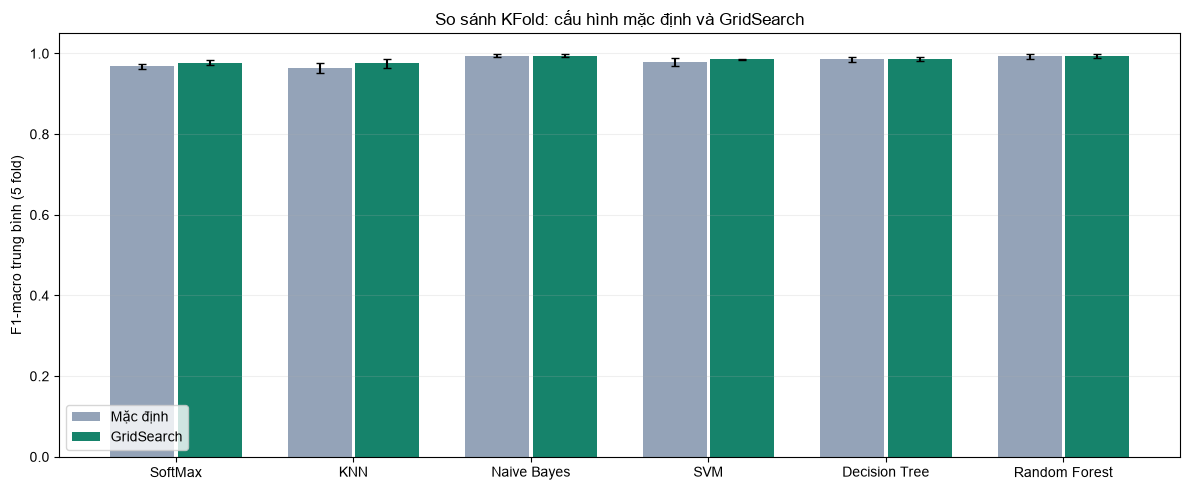

In [10]:
training_summary = pd.DataFrame(summary_rows)
fold_results = pd.DataFrame(fold_rows)
grid_results = pd.DataFrame(grid_rows)
total_training_seconds = sum(training_durations)
print(f"Hoàn thành 6 thuật toán, 12 cấu hình sau {total_training_seconds:.1f} giây.")

grid_definition_rows = []
for name, spec in experiments.items():
    grids = spec["grid"] if isinstance(spec["grid"], list) else [spec["grid"]]
    for grid_number, grid in enumerate(grids, 1):
        for param, values in grid.items():
            grid_definition_rows.append({
                "Model": name, "Grid_group": grid_number,
                "Preprocessing": "StandardScaler trong Pipeline" if spec["scale"] else "Dữ liệu gốc",
                "Parameter": param, "Values": json.dumps(values, ensure_ascii=False),
                "Candidates_model": len(ParameterGrid(spec["grid"])),
            })
grid_definition = pd.DataFrame(grid_definition_rows)
experiment_plan = pd.DataFrame([
    {"Model_number": list(experiments).index(name) + 1, "Model": name, "Scaling": spec["scale"], "Candidates": len(ParameterGrid(spec["grid"])),
     "GridSearch_CV_fits": N_SPLITS * len(ParameterGrid(spec["grid"]))}
    for name, spec in experiments.items()
])
display(experiment_plan)
display(grid_definition)
print("Tổng số lần fit CV:", int(experiment_plan["GridSearch_CV_fits"].sum()) + len(experiments) * N_SPLITS)

display(training_summary[CV_COLUMNS])

fig, ax = plt.subplots(figsize=(12, 5))
positions = np.arange(len(experiments))
for offset, variant, color in [(-0.19, "Mặc định", "#94a3b8"), (0.19, "GridSearch", "#16836b")]:
    data = training_summary[training_summary["Configuration"] == variant].set_index("Model").loc[list(experiments)]
    ax.bar(positions + offset, data["CV_f1_macro_mean"], width=0.36,
           yerr=data["CV_f1_macro_std"], capsize=3, label=variant, color=color)
ax.set(xticks=positions, xticklabels=list(experiments), ylabel="F1-macro trung bình (5 fold)",
       title="So sánh KFold: cấu hình mặc định và GridSearch", ylim=(0, 1.05))
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 8. Lưu checkpoint cho notebook đánh giá

Checkpoint chứa cả 12 pipeline đã fit, kết quả CV từng fold, mọi ứng viên
GridSearch và thông tin tái lập. Đây là dữ liệu trung gian cho notebook 04.

In [11]:
artifact = {
    "model_order": list(experiments), "schema_version": 1, "run_id": run_id, "started_at": started_at,
    "finished_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "random_state": RANDOM_STATE, "n_splits": N_SPLITS, "n_jobs": N_JOBS,
    "cv_method": "StratifiedKFold(shuffle=True, random_state=42)",
    "selection_metric": "f1_macro", "scoring": SCORING,
    "features": X_train.columns.tolist(), "classes": sorted(y_train.unique().tolist()),
    "data_hashes": data_hashes, "train_samples": len(X_train),
    "training_seconds": total_training_seconds,
    "versions": {"Python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "fitted_models": fitted_models, "training_summary": training_summary,
    "fold_results": fold_results, "grid_results": grid_results,
    "grid_definition": grid_definition, "fold_summary": fold_summary,
}
joblib.dump(artifact, checkpoint_path, compress=3)
print("Đã lưu checkpoint:", checkpoint_path)
print("Tiếp theo: chạy notebook 04_model_evaluation.ipynb để đánh giá test và xuất Excel.")

Đã lưu checkpoint: D:\HK1_Nam3\MachineLearning\Crop_Recommendation_System\notebooks\model_training_results.joblib
Tiếp theo: chạy notebook 04_model_evaluation.ipynb để đánh giá test và xuất Excel.
